**EEG–Eye-Tracking Multimodal Research | Presented by: Reza Saadatyar (2026)**

**01 | ZuCo 2.0 Source Audit and Experimental Protocol**

![Recorded ZuCo 2.0 source inventory, acquisition metadata and participant roles](../../images/01_zuco_source_audit_and_protocol.svg)

**Research question:** Which ZuCo 2.0 recordings supply paired Normal Reading (NR) and Task-Specific Reading (TSR) EEG and eye-tracking source files, and how can the expanded cohort preserve the roles of participants previously assessed in the six-person pilot?

**Objective:** Audit the original BIDS filenames and source packages, record EEG/EyeLink acquisition metadata, and establish a reproducible, participant-disjoint Train/Validation/reserved-Test protocol before temporal alignment and signal-quality screening.

**Dataset and task boundary:** ZuCo 2.0, NEMAR `nm000279`, release `v1.0.0`. The supervised target is **original reading-task condition (NR versus TSR)**, not measured comprehension, mental workload or a clinical outcome. Each selected participant contributes **NR Run 1** and **TSR Run 1**.

**Executed Stage-01 evidence:** The BIDS filename audit identified **18/18 paired-file-eligible participants**. All **36 source-run packages** were reported present, totalling **3,373.4 MB (approximately 3.14 GiB)**. Acquisition sidecars report **128 EEG channels** and nominal **500-Hz sampling for both EEG and EyeLink**; eye `StartTime` offsets range from **−0.046 to +0.033 seconds**.

**Approved split, now executed and reconciled:** **11 Train / 3 Validation / 4 reserved Test participants** (22/6/8 original NR/TSR runs). All **six** previously assessed pilot roles were retained. The recorded `01_protocol.json`, `01_split_assignments.csv`, `01_source_manifest.csv` and `01_source_eligibility.csv` agree on the selected cohort and participant identities.

**Scientific limits:** This stage confirms **source presence, file retrieval and acquisition metadata**, not 18-person paired-window eligibility, independent EEG–eye clock-drift correction, eye-calibration quality or predictive generalisation. The current `02_*`–`06_*` files still describe the **earlier six-person pilot** and must be regenerated sequentially for the expanded cohort. **No held-out Test scoring was performed.**


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")

if not repo_path.exists():
    subprocess.run(
        ["git", "clone", "-q", repo_url, str(repo_path)], check=True
    )

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eeg_eye_tracking_fusion")

# ---------------------------- 2. Standard Library ----------------------------
import importlib.util
import json
import random
import shutil
import sys

# ---------------------- 3. Colab Dependency Preparation ----------------------
if importlib.util.find_spec("mne") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "-q", "install",
         "mne>=1.6,<2"],
        check=True,
    )

# ----------------- 4. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 5. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style

# ----------------- 6. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from zuco_io import (
    DATASET_ID, VERSION, metadata_table, discover_cohort,
    session, expanded_cohort_roles, PILOT_ROLE_LOCK, fetch_run, read_sidecar,
)

# ---------------------------- 7. Reproducibility -----------------------------
SEED = 17
random.seed(SEED)
np.random.seed(SEED)

# ------------------- 8. Output Directory and Setup Summary -------------------
work = root / "eeg_eye_tracking_fusion"
output_dir = work / "output"
output_dir.mkdir(parents=True, exist_ok=True)
raw_dir = Path("/content/zuco2_source_cache")
raw_dir.mkdir(parents=True, exist_ok=True)
plot_style(font_family="DejaVu Sans", figure_dpi=100)
print("Project outputs:", output_dir)
print("Temporary source cache:", raw_dir)
print("Python:", sys.version.split()[0])
print("Free disk (GiB):", round(
    shutil.disk_usage("/content").free / 2**30, 2,
))


Repository updated.
Project outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eeg_eye_tracking_fusion/output
Temporary source cache: /content/zuco2_source_cache
Python: 3.13.18
Free disk (GiB): 104.0


**02. Configure and Audit Original Source Metadata**

**Implemented input control:** `MAX_PARTICIPANTS = 18` selects the number of participants from the currently audited source pool (six to eighteen supported while keeping all pilot participants). `RUNS_PER_TASK = 1` retains one original NR and one TSR recording per person. The fixed `SEED = 17` governs reproducible allocation of additional participants; no scientific acquisition or feature setting is modified by changing the size control.

The source discovery routine checks for the required **eight BIDS files per Run-1 recording**, including BrainVision EEG/header/markers, EEG metadata, events, channels and EyeLink physiology/metadata. The `01_source_eligibility.csv` table records whether each indexed person has complete paired source filenames and whether they are included in the selected cohort.

**Observed source inventory:** **18 participants**, all **eligible and selected**, supplied **36 NR/TSR Run-1 records**. No participant was excluded at the **filename-availability** stage. This does **not** guarantee adequate EEG/eye recording length, valid gaze coordinates, clean EEG or verified cross-device timing.

**Recorded provenance:** `01_protocol.json` now includes `selected_people=18`, `eligible_source_pool=18`, `role_policy` and the exact `pilot_role_lock`; these were checked against the saved participant assignments.


In [3]:
# ============== 02. Configure Source and Read Dataset Metadata ===============

# The only routinely changed cohort-size setting (6–18 currently audited).
# Keep RUNS_PER_TASK at 1 unless a separate run-coverage audit is approved.
MAX_PARTICIPANTS = 18
RUNS_PER_TASK = 1
if MAX_PARTICIPANTS < len(PILOT_ROLE_LOCK):
    raise ValueError("The expanded run must retain all six pilot participants")
REQUEST = session()
participants = metadata_table('participants.tsv', REQUEST)
source, eligibility = discover_cohort(
    max_participants=MAX_PARTICIPANTS,
    runs_per_task=RUNS_PER_TASK, handle=REQUEST)
print('Source participants:', len(participants))
eligible_pool = eligibility.loc[
    eligibility.eligible, 'participant_id'].astype(str).tolist()
selected_people = source.participant_id.nunique()
if selected_people != MAX_PARTICIPANTS:
    raise ValueError(
        f'Requested {MAX_PARTICIPANTS} participants, but only '
        f'{selected_people} have complete paired source files; '
        'review eligibility before reducing the cohort.')
print('Selected people:', selected_people)
print('Complete paired-source eligible people:', len(eligible_pool))
display(eligibility)
display(source[['participant_id', 'task', 'run']])


Source participants: 18
Selected people: 18
Complete paired-source eligible people: 18


,participant_id,eligible,reason
0,sub-YAC,True,complete
1,sub-YAG,True,complete
2,sub-YAK,True,complete
3,sub-YDG,True,complete
4,sub-YDR,True,complete
5,sub-YFR,True,complete
6,sub-YFS,True,complete
7,sub-YHS,True,complete
8,sub-YIS,True,complete
9,sub-YLS,True,complete


,participant_id,task,run
0,sub-YAC,nr,1
1,sub-YAC,tsr,1
2,sub-YAG,nr,1
3,sub-YAG,tsr,1
4,sub-YAK,nr,1
5,sub-YAK,tsr,1
6,sub-YDG,nr,1
7,sub-YDG,tsr,1
8,sub-YDR,nr,1
9,sub-YDR,tsr,1


**03. Define Participant-Disjoint Train, Validation and Test**

The **participant**, rather than the recording or 12-second window, is the independent splitting unit. Each selected person contributes both original source tasks to **one and only one** partition. This prevents direct person overlap between training, model selection and the reserved final Test.

The executed `expanded_cohort_roles` policy first retains the **six-person pilot assignments**, then deterministically assigns additional eligible people using the full source pool and seed **17**. Because the additional-person allocation is planned from that pool, increasing or reducing `MAX_PARTICIPANTS` within the currently supported range does not reshuffle previously assigned participants.

| Split | Independent people | NR runs | TSR runs | Participant IDs |
| --- | ---: | ---: | ---: | --- |
| **Train** | **11** | 11 | 11 | `sub-YAK`, `sub-YDG`, `sub-YFR`, `sub-YFS`, `sub-YHS`, `sub-YIS`, `sub-YLS`, `sub-YMS`, `sub-YRK`, `sub-YSD`, `sub-YSL` |
| **Validation** | **3** | 3 | 3 | `sub-YDR`, `sub-YRH`, `sub-YTL` |
| **Test (reserved)** | **4** | 4 | 4 | `sub-YAC`, `sub-YAG`, `sub-YMD`, `sub-YRP` |
| **Total** | **18** | **18** | **18** | No duplicated participant IDs across roles |

**Reconciled pilot-role lock:** `sub-YAK`, `sub-YDG`, `sub-YFR` remain in Train; `sub-YDR` remains in Validation; `sub-YAC`, `sub-YAG` remain in Test. The source Manifest, eligibility table, role CSV and protocol agree with these assignments.

**Interpretation:** This is a **prospectively frozen participant allocation**, not an indication that all people will pass Stage-02 signal-quality screening. The four Test people remain excluded from model fitting and selection. A change to data inclusion or split roles after reviewing model results requires a clearly documented new development protocol.


In [4]:
# ================ 03. Define Participant-Disjoint Partitions =================

# Earlier assessed Train/Validation/Test people retain their exact roles.
# Additional people are assigned using the full eligible source pool,
# not re-shuffled whenever MAX_PARTICIPANTS changes.
roles = expanded_cohort_roles(
    source.participant_id, eligible_pool, seed=SEED)
eligibility['selected_for_cohort'] = (
    eligibility.participant_id.astype(str).isin(roles.participant_id))
eligibility['split'] = (
    eligibility.participant_id.astype(str).map(
        roles.set_index('participant_id').split))
if not all(roles.set_index('participant_id').loc[
        subject, 'split'] == role
        for subject, role in PILOT_ROLE_LOCK.items()):
    raise ValueError('Previously assessed pilot role was changed')
source = source.merge(roles, on='participant_id', validate='many_to_one')
# These are scientific requirements, not administrative fixed-count assertions.
task_coverage = source.groupby("participant_id")["task"].nunique()
role_coverage = source.groupby("participant_id")["split"].nunique()
if task_coverage.ne(2).any():
    raise ValueError("Selected participants must each have NR and TSR runs")
if role_coverage.ne(1).any():
    raise ValueError("A participant appears in more than one split")
print("Participants with both source tasks:", int(task_coverage.eq(2).sum()))
print("Participants with one assigned role:", int(role_coverage.eq(1).sum()))
print("Pilot roles preserved:", len(PILOT_ROLE_LOCK))
print("Additional participants:", len(roles) - len(PILOT_ROLE_LOCK))
display(roles.groupby('split').size().rename('n_people'))
display(source.groupby(["split", "task"]).size().rename("n_runs"))


Participants with both source tasks: 18
Participants with one assigned role: 18
Pilot roles preserved: 6
Additional participants: 12


,n_people
split,
test,4
train,11
validation,3


split       task
test        nr       4
            tsr      4
train       nr      11
            tsr     11
validation  nr       3
            tsr      3
Name: n_runs, dtype: int64

**04. Retrieve Selected EEG and Eye-Tracking Source Runs**

The acquisition routine retrieves only the original source files listed in the selected `01_source_manifest.csv` records. Each Run-1 package contains **eight BIDS files**: BrainVision EEG, header, markers and EEG metadata, events and channels tables, plus EyeLink physiology and its metadata sidecar. Selected source files are held in the temporary Colab cache `/content/zuco2_source_cache`, **not** committed as raw recordings to GitHub.

**Observed retrieval:** **36/36 packages** were recorded as complete, covering **18 NR and 18 TSR runs**. The sum of `01_download_inventory.csv` source-package sizes is **3,373.4 MB** (approximately **3.14 GiB**). The smallest package is **`sub-YAK / NR`, 3.95 MB**; its short duration was already identified in the historical pilot and must be evaluated again in the expanded Stage-02 quality audit.

**Reproducibility and limits:** The download helper can reuse complete local files in the same Colab Runtime. A new Runtime may require the original source files to be retrieved again. Presence and byte counts do not establish eye-coordinate quality, artefact-free EEG, successful eye calibration or the number of usable paired windows.

The file manifest and acquisition inventory agree on **36 unique participant/task/Run-1 combinations**.


In [5]:
# ================= 04. Retrieve Only Selected Original Runs ==================

acquired = []
for _, run in source.iterrows():
    parts = fetch_run(run, raw_dir, REQUEST)
    size_mb = sum(p.stat().st_size for p in parts.values()) / 1e6
    acquired.append({
        'participant_id': run.participant_id,
        'task': run.task, 'run': int(run.run),
        'source_megabytes': size_mb,
        'all_files_present': all(p.exists() for p in parts.values())
    })
    print(run.participant_id, run.task,
          f'run={int(run.run)}', f'{size_mb:.1f} MB')
acquired = pd.DataFrame(acquired)
if not acquired.all_files_present.all():
    raise RuntimeError("A selected original run has missing source files")
print("Downloaded source runs:", len(acquired))
print("Total retrieved source volume (MB):",
      round(acquired.source_megabytes.sum(), 1))
print("Smallest run (MB):", round(acquired.source_megabytes.min(), 2))


sub-YAC nr run=1 116.5 MB
sub-YAC tsr run=1 88.0 MB
sub-YAG nr run=1 179.7 MB
sub-YAG tsr run=1 165.9 MB
sub-YAK nr run=1 3.9 MB
sub-YAK tsr run=1 68.6 MB
sub-YDG nr run=1 102.8 MB
sub-YDG tsr run=1 49.4 MB
sub-YDR nr run=1 110.9 MB
sub-YDR tsr run=1 36.4 MB
sub-YFR nr run=1 130.1 MB
sub-YFR tsr run=1 83.3 MB
sub-YFS nr run=1 100.5 MB
sub-YFS tsr run=1 37.1 MB
sub-YHS nr run=1 73.7 MB
sub-YHS tsr run=1 22.3 MB
sub-YIS nr run=1 118.6 MB
sub-YIS tsr run=1 46.7 MB
sub-YLS nr run=1 142.7 MB
sub-YLS tsr run=1 110.1 MB
sub-YMD nr run=1 141.7 MB
sub-YMD tsr run=1 79.5 MB
sub-YMS nr run=1 167.4 MB
sub-YMS tsr run=1 38.8 MB
sub-YRH nr run=1 115.7 MB
sub-YRH tsr run=1 58.9 MB
sub-YRK nr run=1 147.4 MB
sub-YRK tsr run=1 103.6 MB
sub-YRP nr run=1 129.4 MB
sub-YRP tsr run=1 99.4 MB
sub-YSD nr run=1 99.4 MB
sub-YSD tsr run=1 36.3 MB
sub-YSL nr run=1 143.1 MB
sub-YSL tsr run=1 78.7 MB
sub-YTL nr run=1 114.6 MB
sub-YTL tsr run=1 32.3 MB
Downloaded source runs: 36
Total retrieved source volume (MB): 33

**05. Inspect EEG and Eye-Tracking Acquisition Metadata**

This stage reads the acquisition JSON sidecars for every selected recording. It reports native sampling frequencies, EEG channel counts, EyeLink column names and the relative `StartTime` recorded for the eye-physiology stream.

**Observed across 36 runs:** Each EEG sidecar reports **128 channels**, with nominal EEG sampling at **500 Hz**; all paired EyeLink sidecars also report **500 Hz**. EyeLink columns include `eye1_x_coordinate`, `eye1_y_coordinate` and `eye1_pupil_size`. The relative eye start-offset range is **−0.046 to +0.033 s** across the NR/TSR source packages.

**What this establishes:** The required metadata are consistently available and can support BIDS-relative temporal pairing in Notebook 02.

**What this does not establish:** Equal nominal sample rates and small reported offsets do not independently verify clock synchronisation, time drift, valid gaze samples or ocular artefact control. Notebook 02 must assess actual EEG and eye recording durations, time overlap, source events and finite-coordinate window coverage for every selected person/task run.


In [6]:
# =========== 05. Inspect EEG and Eye-Tracking Acquisition Metadata ===========

checks = []
for _, run in source.iterrows():
    eeg = read_sidecar(raw_dir / run.eeg_json)
    eye = read_sidecar(raw_dir / run.eye_json)
    checks.append({
        'participant_id': run.participant_id, 'task': run.task,
        'run': int(run.run),
        'eeg_sfreq': float(eeg['SamplingFrequency']),
        'eye_sfreq': float(eye['SamplingFrequency']),
        'eeg_channels': int(eeg['EEGChannelCount']),
        'eye_start_time': float(eye['StartTime']),
        'eye_columns': ','.join(eye['Columns'])
    })
source_metadata = pd.DataFrame(checks)
display(source_metadata.groupby('task')[[
    'eeg_sfreq', 'eye_sfreq', 'eeg_channels']].describe())


eeg_sfreq                                                eye_sfreq  \
         count   mean  std    min    25%    50%    75%    max     count   
task                                                                      
nr        18.0  500.0  0.0  500.0  500.0  500.0  500.0  500.0      18.0   
tsr       18.0  500.0  0.0  500.0  500.0  500.0  500.0  500.0      18.0   

             ...               eeg_channels                                   \
       mean  ...    75%    max        count   mean  std    min    25%    50%   
task         ...                                                               
nr    500.0  ...  500.0  500.0         18.0  128.0  0.0  128.0  128.0  128.0   
tsr   500.0  ...  500.0  500.0         18.0  128.0  0.0  128.0  128.0  128.0   

                    
        75%    max  
task                
nr    128.0  128.0  
tsr   128.0  128.0  

[2 rows x 24 columns]

**06. Visualise Cohort Composition and Save Source Evidence**

The executed source overview `01_source_overview.png` shows the **number of original NR and TSR runs within each participant partition**, using the saved, pilot-preserving **11 Train / 3 Validation / 4 reserved Test** assignment. Because each person has one Run 1 per task, the plot contains **11+11 Train, 3+3 Validation and 4+4 Test recordings**. It visualises **source-run support**, not window counts or model accuracy.

**Seven owned outputs from the recorded Stage-01 run:**

| File | Content and scope |
| --- | --- |
| `01_source_manifest.csv` | 36 source-run identities, eight BIDS-relative paths per run and frozen participant roles |
| `01_split_assignments.csv` | One role per each of 18 participants |
| `01_source_eligibility.csv` | Paired source-file eligibility, selected cohort and assigned role |
| `01_download_inventory.csv` | 36 recorded source-package sizes and presence flags |
| `01_acquisition_metadata.csv` | 36 rows of EEG/EyeLink sampling, channel and time-offset metadata |
| `01_protocol.json` | Dataset version, target mapping, selected/eligible counts, pilot-role lock, split counts and downstream window settings |
| `01_source_overview.png` | Descriptive Train/Validation/Test source-run counts by original reading task |

**Reconciliation:** The role CSV has **18 unique people**, the manifest has **36 distinct person/task/run IDs**, all 36 packages are marked present, and source-role/eligibility/protocol identities agree. The saved source plot is not evidence of signal-quality eligibility. A separately uploaded ZIP may duplicate these outputs but is not an additional scientific result.


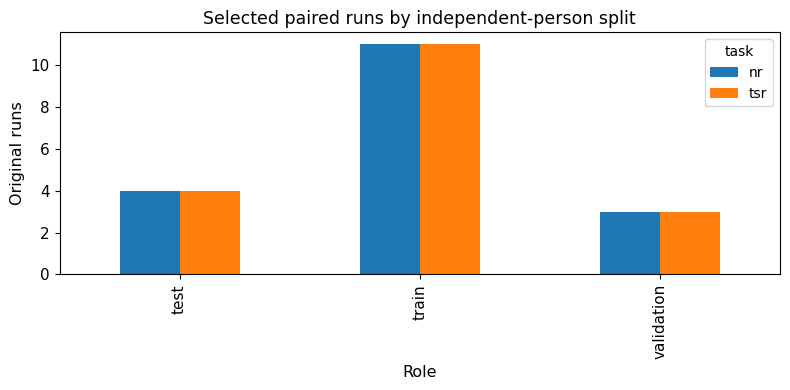

Saved Stage 01 outputs: 7


In [7]:
# ========= 06. Visualise Cohort Composition and Save Stage Evidence ==========

source.to_csv(output_dir / '01_source_manifest.csv', index=False)
roles.to_csv(output_dir / '01_split_assignments.csv', index=False)
eligibility.to_csv(output_dir / '01_source_eligibility.csv', index=False)
source_metadata.to_csv(output_dir / '01_acquisition_metadata.csv',
                       index=False)
acquired.to_csv(output_dir / '01_download_inventory.csv', index=False)
protocol = {
    'dataset_id': DATASET_ID, 'dataset_version': VERSION,
    'target': {'nr': 0, 'tsr': 1},
    'max_participants': int(MAX_PARTICIPANTS),
    'selected_people': int(roles.participant_id.nunique()),
    'eligible_source_pool': int(len(eligible_pool)),
    'role_policy': 'pilot_roles_locked_full_pool_seeded_expansion',
    'pilot_role_lock': dict(PILOT_ROLE_LOCK),
    'runs_per_task': int(RUNS_PER_TASK),
    'seed': SEED,
    'participant_split': roles.groupby('split').size().to_dict(),
    'window_seconds': 12., 'bin_seconds': 2.,
    'max_windows_per_run': 20, 'min_eye_fraction': 0.6,
    'final_test_policy': 'select using Validation, then score Test'
}
(output_dir / '01_protocol.json').write_text(
    json.dumps(protocol, indent=2), encoding='utf-8')
fig, ax = plt.subplots(figsize=(8, 4))
source.groupby(['split', 'task']).size().unstack(fill_value=0).plot(
    kind='bar', ax=ax)
ax.set(title='Selected paired runs by independent-person split',
       xlabel='Role', ylabel='Original runs')
fig.tight_layout()
fig.savefig(output_dir / '01_source_overview.png', dpi=170)
plt.show()
print('Saved Stage 01 outputs:', len(list(output_dir.glob('01_*'))))


**07. Interpretation and Downstream Dependency**

**Stage-01 conclusion:** The expanded ZuCo 2.0 **18-person Run-1 source audit and participant-split protocol are complete at the source-evidence level**. All 18 source participants have complete paired BIDS filenames and all 36 selected packages were retrieved. Each run reports 128-channel EEG and nominal 500-Hz EEG and eye acquisition. The approved **11 Train / 3 Validation / 4 reserved Test** participant roles are now saved consistently; all original six-person pilot assignments remain unchanged.

**Recorded scientific boundary:** NR and TSR are **reading-task conditions**. The present results establish no cognition measure, signal-quality finding, fusion advantage or held-out generalisation. Paired-window eligibility for the additional 12 people has **not** yet been observed. Source-start metadata do not independently validate inter-device timing drift.

**Next stage:** Execute [Notebook 02: EEG–Gaze Alignment and Paired-Window Quality](02_eeg_gaze_alignment_and_quality.ipynb) using the **current 18-person Stage-01 outputs**, not the historical six-person registry. It must check all 36 original source runs for sufficient EEG/eye overlap, event support and finite-coordinate coverage before generating a new **12-second paired-window registry**. If any person/task run has no eligible window, review that specific quality finding rather than silently changing the cohort or dropping Test participants.

**Execution boundary:** All current `02_*`–`06_*` results are still **historical six-person pilot evidence** until each stage is rerun and reviewed. **Test scoring remains disabled.**


In [8]:
# ================== 07. Interpretation and Next Dependency ===================

print("Selected independent participants:",
      source.participant_id.nunique())
print("Registered split participants:", roles.participant_id.nunique())
print("Original NR/TSR runs:", len(source))
print("Complete downloaded run packages:",
      int(acquired.all_files_present.sum()), "/", len(acquired))

print("Next: 02_eeg_gaze_alignment_and_quality.ipynb")

download_outputs_from_colab("eeg_eye_tracking_fusion/output", "01")


Selected independent participants: 18
Registered split participants: 18
Original NR/TSR runs: 36
Complete downloaded run packages: 36 / 36
Next: 02_eeg_gaze_alignment_and_quality.ipynb
------------------------------------------------------------------------
Notebook 01
Files packaged: 7
  + 01_acquisition_metadata.csv
  + 01_download_inventory.csv
  + 01_protocol.json
  + 01_source_eligibility.csv
  + 01_source_manifest.csv
  + 01_source_overview.png
  + 01_split_assignments.csv
Download ZIP from Colab Contents: /content/eeg_eye_tracking_fusion_Notebook_01_Outputs.zip
